<a href="https://colab.research.google.com/github/hacaizacr/sp500_trend_classifier/blob/main/PROYECTO_INTEGRADOR_Modelos_finalizados.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicción del rendimiento relativo de empresas del S&P 500 frente a RSP
### Proyecto de Machine Learning · Grupo 2

## Resumen del proyecto
**Pregunta:** dados los indicadores financieros de una empresa del S&P 500, ¿cuál es la probabilidad de que su acción supere al ETF **RSP** (S&P 500 equiponderado) durante los siguientes 12 meses?

**Tipo de problema:** clasificación binaria probabilística. `Target = 1` si la acción superó a RSP, `Target = 0` si no.

**Modelos comparados:** Logistic Regression, Random Forest y XGBoost, con exactamente los mismos datos, la misma separación temporal y las mismas variables.

**Archivos:** `dataset_modelo.csv` (entrenamiento) y `dataset_trazabilidad.csv` (solo para leer las fechas y purgar horizontes solapados; nunca como predictor).

## Decisiones clave

| Decisión | Por qué |
|---|---|
| Separación **cronológica** (train ≤ 2021, test ≥ 2022) | En series de tiempo, una división aleatoria mezclaría el futuro con el pasado y daría resultados artificialmente buenos. |
| **Purga** de horizontes solapados | Una observación de 2021 mide el retorno de los 12 meses siguientes, que caen en 2022. Si se entrena con ella, se usa información del periodo de prueba. |
| **Validación temporal progresiva** | Para elegir hiperparámetros sin tocar el conjunto de prueba: se entrena con años pasados y se valida en el año siguiente. |
| Preprocesamiento **dentro de un Pipeline** | El escalador, el imputador y la winsorización se ajustan solo con datos de entrenamiento (sin fuga). |
| Selección del modelo por **ROC-AUC + Brier + calibración**, no por Accuracy | El objetivo es producir probabilidades confiables, no solo clasificar. |

## Glosario de métricas
- **Accuracy:** % de aciertos con umbral 50 %. Engañosa si las clases no están balanceadas.
- **Precision / Recall / F1:** de los que el modelo dice que superan a RSP, cuántos acierta (precision); de los que realmente superan, cuántos encuentra (recall); F1 combina ambas.
- **ROC-AUC:** capacidad de ordenar: probabilidad de que una acción ganadora reciba mayor probabilidad que una perdedora. 0.5 = azar.
- **Brier Score:** error cuadrático medio de las probabilidades (menor es mejor). Predecir siempre la prevalencia da ≈ 0.25.
- **Calibración / ECE:** si cuando el modelo dice "60 %" realmente ocurre ~60 % de las veces. ECE es la diferencia promedio entre probabilidad predicha y frecuencia real.

## 1. Importaciones y configuración

In [ ]:
import os, json, shutil, warnings, importlib, sys
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             brier_score_loss, log_loss, average_precision_score, ConfusionMatrixDisplay,
                             classification_report, roc_curve, precision_recall_curve)
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

SEED = 42                  # semilla única para que los resultados sean reproducibles
np.random.seed(SEED)
ANIO_CORTE = 2021          # entrenamiento: Anio_Obs <= 2021 | prueba: Anio_Obs >= 2022
UMBRAL = 0.5               # umbral de decisión
PURGAR = True              # quitar del entrenamiento las filas cuyo horizonte invade la prueba
ANIOS_VAL = [2017, 2018, 2019, 2020]   # años usados como validación temporal
COLORES = {'Logistic Regression': '#2E86AB', 'Random Forest': '#2E9E5B', 'XGBoost': '#E07A1F'}

def ruta(nombre):
    """Busca el archivo en carpetas habituales; en Colab pide subirlo si no lo encuentra."""
    for d in ['.', '/content', '/content/drive/MyDrive']:
        if os.path.exists(os.path.join(d, nombre)):
            return os.path.join(d, nombre)
    from google.colab import files
    print(f'Sube el archivo {nombre}')
    files.upload()
    return nombre

## 2. Carga y exploración del dataset
**Qué hacemos:** cargar los datos, comprobar que las columnas coinciden con las especificaciones y explorar la distribución del Target y de las variables.

**Qué buscar:** nulos, columnas problemáticas, balance de clases y correlaciones. Una correlación muy alta con Target sería señal de fuga de información.

In [ ]:
df = pd.read_csv(ruta('dataset_modelo.csv'))
TARGET, ANIO = 'Target', 'Anio_Obs'
CONT = ['Revenue_Growth', 'Net_Income', 'Profit_Margin', 'Debt_to_Equity', 'PE_Ratio']   # variables continuas
BIN = ['Patrimonio_Negativo', 'Perdidas']                                                # indicadores 0/1
SECT = [c for c in df.columns if c.startswith('GICS Sector_')]                          # one-hot de sectores
FEATURES = CONT + BIN + SECT                       # Anio_Obs y Target quedan fuera de X
ORDEN = CONT + [c for c in FEATURES if c not in CONT]   # orden de columnas tras el ColumnTransformer
SECTORES = [c.replace('GICS Sector_', '') for c in SECT]
corto = lambda c: c.replace('GICS Sector_', 'Sector: ')

# Verificación automática: no hay columnas extra ni faltantes
assert set(df.columns) == set(FEATURES + [TARGET, ANIO]), 'Las columnas no coinciden con lo esperado'

print('Dimensiones:', df.shape)
print('Nulos totales:', df.isna().sum().sum(), '| Filas duplicadas:', df.duplicated().sum())
print('Cada fila pertenece a un solo sector:', (df[SECT].sum(axis=1) == 1).all())
display(df.dtypes.to_frame('dtype').T)
display(df[CONT].describe().T.round(2))

Dimensiones: (4825, 20)
Nulos totales: 0 | Filas duplicadas: 10
Cada fila pertenece a un solo sector: True


,Anio_Obs,Revenue_Growth,Net_Income,Profit_Margin,Debt_to_Equity,PE_Ratio,Patrimonio_Negativo,Perdidas,GICS Sector_Communication Services,GICS Sector_Consumer Discretionary,GICS Sector_Consumer Staples,GICS Sector_Energy,GICS Sector_Financials,GICS Sector_Health Care,GICS Sector_Industrials,GICS Sector_Information Technology,GICS Sector_Materials,GICS Sector_Real Estate,GICS Sector_Utilities,Target
dtype,int64,float64,float64,float64,float64,float64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64


,count,mean,std,min,25%,50%,75%,max
Revenue_Growth,4825.0,6.95,18.11,-73.43,-0.37,5.19,11.83,151.83
Net_Income,4825.0,2719.43,5747.39,-10058.40,521.70,1128.00,2655.05,66883.60
Profit_Margin,4825.0,13.10,15.33,-95.65,6.32,11.34,18.21,128.57
Debt_to_Equity,4825.0,1.24,2.18,0.00,0.47,0.70,1.17,28.38
PE_Ratio,4825.0,32.96,55.59,4.07,16.11,23.03,32.72,1044.92


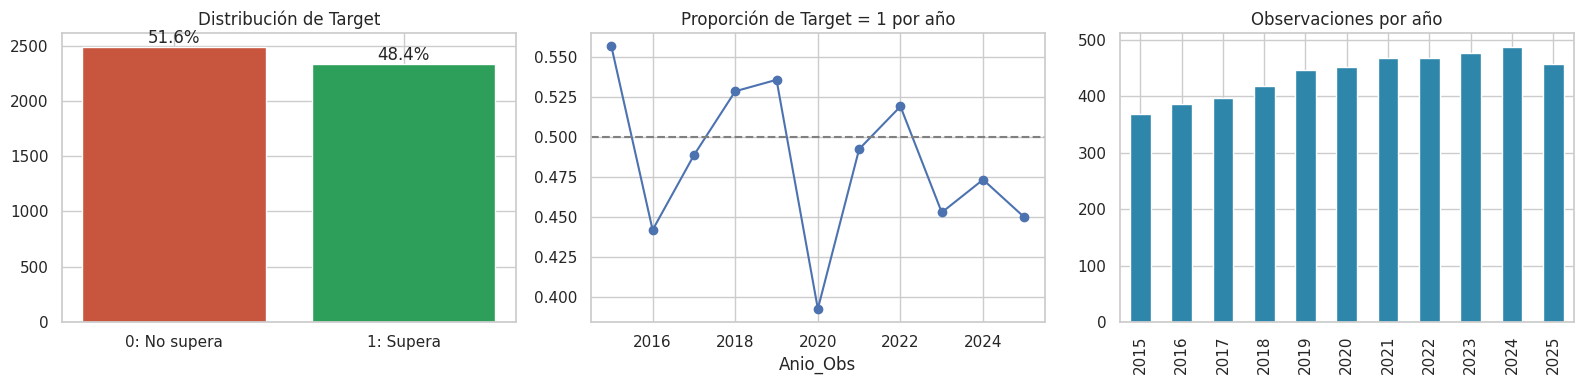

In [ ]:
# Distribución del Target, proporción por año y número de observaciones por año
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

conteo = df[TARGET].value_counts().sort_index()
ax[0].bar(['0: No supera', '1: Supera'], conteo.values, color=['#C8553D', '#2E9E5B'])
for i, v in enumerate(conteo.values):
    ax[0].text(i, v, f'{v / len(df):.1%}', ha='center', va='bottom')
ax[0].set_title('Distribución de Target')

df.groupby(ANIO)[TARGET].mean().plot(marker='o', ax=ax[1])
ax[1].axhline(0.5, color='gray', ls='--'); ax[1].set_title('Proporción de Target = 1 por año')

df[ANIO].value_counts().sort_index().plot.bar(ax=ax[2], color='#2E86AB')
ax[2].set_title('Observaciones por año'); ax[2].set_xlabel('')
plt.tight_layout(); plt.show()

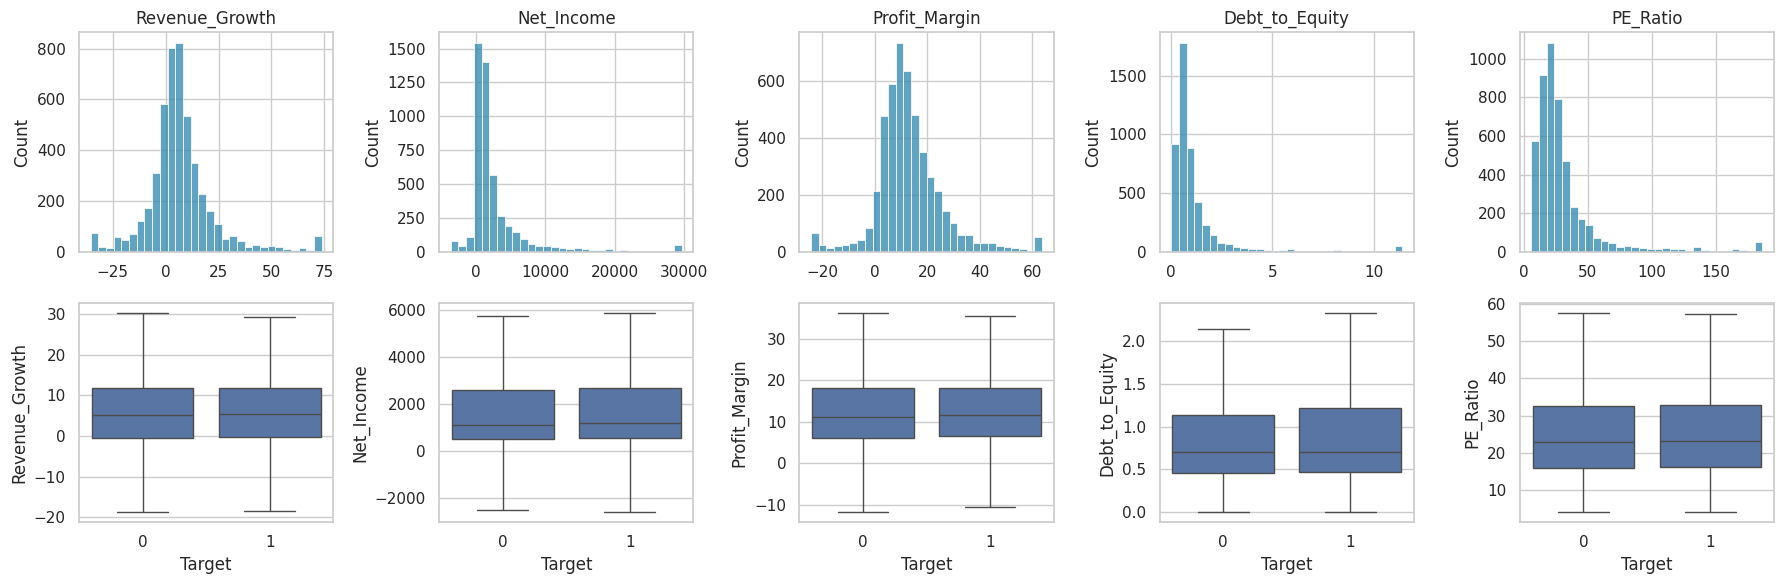

In [ ]:
# Variables continuas: distribución y relación con Target
fig, ax = plt.subplots(2, 5, figsize=(18, 6))
for j, c in enumerate(CONT):
    lo, hi = df[c].quantile([0.01, 0.99])          # recorte solo para graficar
    sns.histplot(df[c].clip(lo, hi), bins=30, ax=ax[0, j], color='#2E86AB'); ax[0, j].set_title(c); ax[0, j].set_xlabel('')
    sns.boxplot(data=df, x=TARGET, y=c, ax=ax[1, j], showfliers=False)
plt.tight_layout(); plt.show()

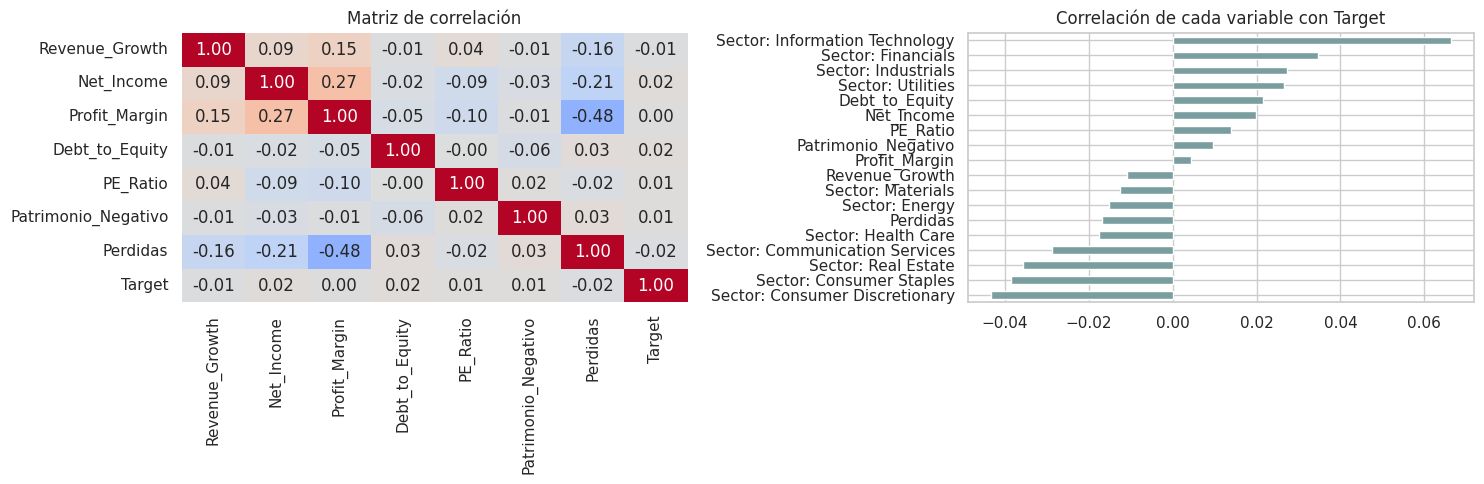

Máxima |correlación| con Target: 0.066  (muy baja: el problema es difícil)


In [ ]:
# Correlaciones: entre variables financieras y de cada variable con Target
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(df[CONT + BIN + [TARGET]].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[0], cbar=False)
ax[0].set_title('Matriz de correlación')

corr_t = df[FEATURES].corrwith(df[TARGET]).sort_values()
corr_t.rename(index=corto).plot.barh(ax=ax[1], color='#7A9E9F')
ax[1].set_title('Correlación de cada variable con Target')
plt.tight_layout(); plt.show()
print(f'Máxima |correlación| con Target: {corr_t.abs().max():.3f}  (muy baja: el problema es difícil)')

**Lectura:** el Target está casi balanceado (≈ 52 % / 48 %) y todas las correlaciones con Target son muy bajas. Esto es esperable: predecir rendimientos bursátiles es difícil, y un ROC-AUC cercano a 0.55 ya sería realista. Si apareciera un resultado muy superior (≥ 0.80), habría que sospechar de fuga de información.

## 3. Preparación de datos

### 3.1 Revisión de fuga de información en la limpieza previa
| Operación previa | Cómo se hizo | ¿Fuga hacia la prueba? |
|---|---|---|
| Winsorización p1–p99 | Por año de observación | No: cada año usa solo sus propios datos y los años de entrenamiento y prueba son distintos. |
| Imputación de nulos | Mediana de (sector, año) | No, por la misma razón. |
| Sector de empresas fuera del índice | Recuperado de Yahoo Finance | Evita que "estar fuera del índice hoy" sea un predictor. |
| Horizonte de 12 meses | `Fecha_Fin = Fecha_Obs + 365 días` | **Sí hay solapamiento**: filas de 2021 miden retornos de 2022. Se corrige con la purga. |

Los valores originales (antes de winsorizar o imputar) no están en el CSV, por lo que esas operaciones no pueden rehacerse. Como compensación, el *pipeline* vuelve a winsorizar (p1–p99) e imputar (mediana) **dentro de cada fold, solo con datos de entrenamiento**.

### 3.2 Separación cronológica y purga

In [ ]:
# dataset_trazabilidad.csv: solo se leen las fechas (NO se usa como variable predictora)
tz = pd.read_csv(ruta('dataset_trazabilidad.csv'), usecols=['Anio_Obs', 'Target', 'Fecha_Obs', 'Fecha_Fin'],
                 parse_dates=['Fecha_Obs', 'Fecha_Fin'])
assert (tz['Anio_Obs'].values == df[ANIO].values).all() and (tz['Target'].values == df[TARGET].values).all(), \
    'Las filas de ambos archivos no están alineadas'

es_train = df[ANIO] <= ANIO_CORTE                 # separación cronológica, sin azar
inicio_test = tz.loc[~es_train, 'Fecha_Obs'].min()
solapa = es_train & (tz['Fecha_Fin'] >= inicio_test)   # filas de entrenamiento cuyo horizonte llega a la prueba
train_mask = es_train & ~solapa if PURGAR else es_train
test_mask = ~es_train

X_train, y_train = df.loc[train_mask, FEATURES].reset_index(drop=True), df.loc[train_mask, TARGET].reset_index(drop=True)
X_test, y_test = df.loc[test_mask, FEATURES].reset_index(drop=True), df.loc[test_mask, TARGET].reset_index(drop=True)
anio_train = df.loc[train_mask, ANIO].reset_index(drop=True)
anio_test = df.loc[test_mask, ANIO].reset_index(drop=True)
obs_train = tz.loc[train_mask, 'Fecha_Obs'].reset_index(drop=True).values
fin_train = tz.loc[train_mask, 'Fecha_Fin'].reset_index(drop=True).values

print(f'La prueba empieza el {inicio_test.date()}. Filas de entrenamiento purgadas: {int(solapa.sum())}')
display(pd.DataFrame({
    'Filas': [es_train.sum(), len(X_train), len(X_test)],
    '% Target=1': [df.loc[es_train, TARGET].mean(), y_train.mean(), y_test.mean()]},
    index=['Entrenamiento bruto (≤ 2021)', 'Entrenamiento final (tras purga)', 'Prueba (≥ 2022)']).round(3))

La prueba empieza el 2022-01-22. Filas de entrenamiento purgadas: 466


,Filas,% Target=1
Entrenamiento bruto (≤ 2021),2934,0.490
Entrenamiento final (tras purga),2468,0.489
Prueba (≥ 2022),1891,0.474


La purga elimina del entrenamiento las observaciones cuyo horizonte de 12 meses termina después del inicio de la prueba. Esto descarta casi todo 2021: es un costo asumido a cambio de una evaluación limpia (se puede desactivar con `PURGAR = False`).

### 3.3 Validación temporal progresiva
Para elegir hiperparámetros **sin usar la prueba**, se usan 4 folds con ventana expansiva: para validar en el año *5* se entrena con los años anteriores (quitando además las filas cuyo horizonte llega al año *5*).

,n entrenamiento,n validación,% Target=1 (validación)
Año de validación,,,
2017,369,397,0.489
2018,757,418,0.529
2019,1153,446,0.536
2020,1570,451,0.392


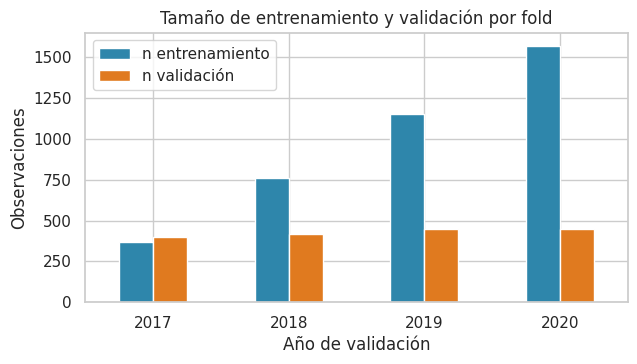

In [ ]:
def splits_temporales(anios, obs, fin, anios_val):
    """Devuelve una lista de (índices de entrenamiento, índices de validación), uno por año de validación."""
    folds = []
    for v in anios_val:
        val = np.where(anios == v)[0]
        inicio_val = obs[val].min()
        train = np.where((anios < v) & (fin < inicio_val))[0]    # años anteriores SIN horizonte solapado
        folds.append((train, val))
    return folds

CV = splits_temporales(anio_train.values, obs_train, fin_train, ANIOS_VAL)
resumen_cv = pd.DataFrame({'n entrenamiento': [len(t) for t, _ in CV], 'n validación': [len(v) for _, v in CV],
                           '% Target=1 (validación)': [y_train.iloc[v].mean() for _, v in CV]}, index=ANIOS_VAL).round(3)
resumen_cv.index.name = 'Año de validación'
display(resumen_cv)
resumen_cv[['n entrenamiento', 'n validación']].plot.bar(figsize=(7, 3.5), color=['#2E86AB', '#E07A1F'])
plt.title('Tamaño de entrenamiento y validación por fold'); plt.ylabel('Observaciones'); plt.xticks(rotation=0); plt.show()

## 4. Preprocesamiento y funciones de apoyo

**Pipeline de preprocesamiento** (se ajusta solo con los datos de entrenamiento de cada fold):
1. `Winsorizer`: recorta las variables continuas a sus percentiles 1 y 99 del entrenamiento.
2. `SimpleImputer`: rellena nulos con la mediana del entrenamiento.
3. `StandardScaler`: estandariza (solo en Logistic Regression; los árboles no lo necesitan).
4. Las variables binarias y one-hot **pasan sin cambios**.

El `Winsorizer` se guarda en un archivo propio (`preprocesamiento.py`) para poder recargar los modelos guardados más adelante.

In [ ]:
codigo_prep = """import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin

class Winsorizer(BaseEstimator, TransformerMixin):
    # Recorta cada columna a los percentiles aprendidos en fit (solo con datos de entrenamiento)
    def __init__(self, lower=0.01, upper=0.99):
        self.lower, self.upper = lower, upper
    def fit(self, X, y=None):
        X = np.asarray(X, float)
        self.lo_ = np.nanquantile(X, self.lower, axis=0)
        self.hi_ = np.nanquantile(X, self.upper, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, float), self.lo_, self.hi_)
"""
with open('preprocesamiento.py', 'w') as f:
    f.write(codigo_prep)
sys.path.insert(0, os.getcwd()); importlib.invalidate_caches()
from preprocesamiento import Winsorizer

def build_pipeline(modelo, escalar):
    """Preprocesamiento de las variables continuas + modelo, todo en un único Pipeline."""
    pasos = [('winsor', Winsorizer()), ('imputer', SimpleImputer(strategy='median'))]
    if escalar:
        pasos.append(('scaler', StandardScaler()))
    pre = ColumnTransformer([('num', Pipeline(pasos), CONT)], remainder='passthrough')   # binarias y sectores intactos
    return Pipeline([('pre', pre), ('model', modelo)])

In [ ]:
SCORING = {'roc_auc': 'roc_auc', 'brier': 'neg_brier_score'}   # se miden ambas; se elige por ROC-AUC

def buscar(pipe, grid, n_iter=None):
    """Búsqueda de hiperparámetros con la validación temporal CV. Se evalúa en folds, nunca en la prueba."""
    if n_iter:
        s = RandomizedSearchCV(pipe, grid, n_iter=n_iter, cv=CV, scoring=SCORING, refit='roc_auc', n_jobs=-1, random_state=SEED)
    else:
        s = GridSearchCV(pipe, grid, cv=CV, scoring=SCORING, refit='roc_auc', n_jobs=-1)
    return s.fit(X_train, y_train)

def tabla_cv(s, top=8):
    """Las mejores configuraciones según el AUC medio de validación."""
    r = pd.DataFrame(s.cv_results_)
    t = pd.DataFrame({'AUC medio': r['mean_test_roc_auc'], 'AUC desv.': r['std_test_roc_auc'], 'Brier medio': -r['mean_test_brier'],
                      'Parámetros': [', '.join(f"{k.replace('model__', '')}={v}" for k, v in p.items()) for p in r['params']]})
    return t.sort_values('AUC medio', ascending=False).head(top).round(4).reset_index(drop=True)

def grafico_cv(s, nombre):
    """AUC de la mejor configuración en cada año de validación."""
    i = s.best_index_
    auc = [s.cv_results_[f'split{k}_test_roc_auc'][i] for k in range(len(CV))]
    plt.figure(figsize=(6, 3.5))
    plt.bar([str(a) for a in ANIOS_VAL], auc, color=COLORES[nombre]); plt.axhline(0.5, color='gray', ls='--')
    plt.ylim(0.4, max(auc) + 0.05); plt.title(f'{nombre}: AUC por año de validación (línea = azar)'); plt.show()

In [ ]:
def ece_score(y, p, bins=10):
    """Error de calibración esperado: diferencia media entre probabilidad predicha y frecuencia real."""
    orden = np.argsort(p); y, p = np.asarray(y)[orden], np.asarray(p)[orden]
    grupos = np.array_split(np.arange(len(p)), bins)
    return sum(len(g) / len(p) * abs(y[g].mean() - p[g].mean()) for g in grupos)

def pendiente_calibracion(y, p):
    """Pendiente de la regresión de y sobre logit(p): 1 = calibrado, <1 = sobreconfiado."""
    q = np.clip(p, 1e-6, 1 - 1e-6)
    return LogisticRegression(C=1e6).fit(np.log(q / (1 - q)).reshape(-1, 1), y).coef_[0, 0]

def metricas(y, p):
    y = np.asarray(y); pred = (p >= UMBRAL).astype(int)
    return {'Accuracy': accuracy_score(y, pred), 'Precision': precision_score(y, pred, zero_division=0),
            'Recall': recall_score(y, pred, zero_division=0), 'F1-Score': f1_score(y, pred, zero_division=0),
            'ROC-AUC': roc_auc_score(y, p), 'Brier Score': brier_score_loss(y, p), 'PR-AUC': average_precision_score(y, p),
            'Log-Loss': log_loss(y, p), 'ECE': ece_score(y, p), 'Pendiente calibración': pendiente_calibracion(y, p)}

In [ ]:
def graficos_evaluacion(nombre, y, p):
    """Seis gráficos estándar de evaluación sobre el conjunto de prueba."""
    y = np.asarray(y); color = COLORES[nombre]
    fig, ax = plt.subplots(2, 3, figsize=(16, 9)); ax = ax.ravel()

    ConfusionMatrixDisplay.from_predictions(y, (p >= UMBRAL).astype(int), ax=ax[0], cmap='Blues', colorbar=False,
                                            display_labels=['No supera', 'Supera'])
    ax[0].set_title('Matriz de confusión'); ax[0].grid(False)

    fpr, tpr, _ = roc_curve(y, p)
    ax[1].plot(fpr, tpr, color=color, label=f'AUC = {roc_auc_score(y, p):.3f}'); ax[1].plot([0, 1], [0, 1], 'k--', label='Azar')
    ax[1].set(title='Curva ROC', xlabel='Falsos positivos', ylabel='Verdaderos positivos'); ax[1].legend()

    prec, rec, _ = precision_recall_curve(y, p)
    ax[2].plot(rec, prec, color=color, label=f'AP = {average_precision_score(y, p):.3f}'); ax[2].axhline(y.mean(), color='k', ls='--', label='Prevalencia')
    ax[2].set(title='Curva Precision-Recall', xlabel='Recall', ylabel='Precision'); ax[2].legend()

    real, pred_media = calibration_curve(y, p, n_bins=8, strategy='quantile')
    ax[3].plot(pred_media, real, 'o-', color=color, label=f'ECE = {ece_score(y, p):.3f}'); ax[3].plot([0, 1], [0, 1], 'k--', label='Calibración perfecta')
    ax[3].set(title='Curva de calibración', xlabel='Probabilidad predicha', ylabel='Frecuencia real'); ax[3].legend()

    ax[4].hist(p[y == 0], bins=25, alpha=.6, color='#C8553D', label='No superó a RSP', density=True)
    ax[4].hist(p[y == 1], bins=25, alpha=.6, color='#2E9E5B', label='Superó a RSP', density=True)
    ax[4].axvline(UMBRAL, color='k', ls='--'); ax[4].set(title='Distribución de probabilidades predichas', xlabel='P(supera a RSP)'); ax[4].legend()

    t = pd.DataFrame({'Predicha': p, 'Real': y})
    t['Quintil'] = pd.qcut(t['Predicha'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5])     # 5 = mayor probabilidad
    g = t.groupby('Quintil').mean()
    g.plot.bar(ax=ax[5], color=[color, 'gray'], rot=0)
    ax[5].set(title='Probabilidad predicha vs resultado real por quintil', ylim=(g.min().min() - .05, g.max().max() + .05))
    ax[5].set_xlabel('Quintil de probabilidad predicha')

    plt.suptitle(f'{nombre}: evaluación en prueba (2022-2025)', fontsize=13, fontweight='bold'); plt.tight_layout(); plt.show()

RES = {}   # aquí se guardan pipeline, probabilidades y métricas de cada modelo

def reporte_modelo(nombre, search):
    """Evalúa el mejor modelo de la búsqueda en el conjunto de prueba y guarda los resultados."""
    pipe = search.best_estimator_
    p = pipe.predict_proba(X_test)[:, 1]
    m = metricas(y_test, p)
    cv_auc = search.cv_results_['mean_test_roc_auc'][search.best_index_]
    RES[nombre] = {'pipe': pipe, 'p': p, 'm': m, 'params': search.best_params_, 'cv_auc': cv_auc}
    print('Mejores hiperparámetros:', search.best_params_)
    print(f'AUC entrenamiento: {roc_auc_score(y_train, pipe.predict_proba(X_train)[:, 1]):.3f} | '
          f'AUC validación temporal: {cv_auc:.3f} | AUC prueba: {m["ROC-AUC"]:.3f}')
    display(pd.Series(m, name=nombre).round(4).to_frame())
    print(classification_report(y_test, (p >= UMBRAL).astype(int), target_names=['No supera RSP', 'Supera RSP'], zero_division=0))
    graficos_evaluacion(nombre, y_test, p)

def grafico_importancias(nombre, pipe, nativa, titulo):
    """Importancia propia del modelo (izquierda) y por permutación en prueba (derecha). Devuelve la de permutación."""
    r = permutation_importance(pipe, X_test, y_test, scoring='roc_auc', n_repeats=30, random_state=SEED, n_jobs=-1)
    perm = pd.DataFrame({'media': r.importances_mean, 'std': r.importances_std}, index=FEATURES)
    fig, ax = plt.subplots(1, 2, figsize=(15, 5))
    nativa.reindex(nativa.abs().sort_values().index).tail(10).rename(index=corto).plot.barh(ax=ax[0], color=COLORES[nombre])
    ax[0].set_title(titulo)
    perm['media'].sort_values().tail(10).rename(index=corto).plot.barh(ax=ax[1], color=COLORES[nombre], alpha=.7)
    ax[1].set_title('Importancia por permutación (caída del AUC en prueba)')
    plt.suptitle(f'{nombre}: variables más influyentes', fontweight='bold'); plt.tight_layout(); plt.show()
    return perm

**Importancia por permutación:** se desordena una variable a la vez y se mide cuánto cae el ROC-AUC. Si la caída es ≈ 0, el modelo no obtiene información útil de esa variable. Se calcula sobre prueba solo para **interpretar**, nunca para elegir hiperparámetros.

## 5. Logistic Regression
**Idea:** modelo lineal que estima la probabilidad con la función logística. Es simple, interpretable y sirve de referencia.

**Hiperparámetros evaluados** (con validación temporal, sin usar la prueba):
- `C`: inverso de la regularización L2 (más pequeño = más regularización = modelo más simple).
- `class_weight`: `None` o `balanced` (dar más peso a la clase minoritaria).

,AUC medio,AUC desv.,Brier medio,Parámetros
0,0.5142,0.0481,0.2636,"C=10.0, class_weight=balanced"
1,0.5141,0.0483,0.2647,"C=100.0, class_weight=None"
2,0.5141,0.0481,0.2639,"C=31.622776601683793, class_weight=balanced"
3,0.5141,0.0481,0.2639,"C=100.0, class_weight=balanced"
4,0.5140,0.0483,0.2646,"C=31.622776601683793, class_weight=None"
5,0.5139,0.0483,0.2644,"C=10.0, class_weight=None"
6,0.5138,0.0481,0.2630,"C=3.1622776601683795, class_weight=balanced"
7,0.5136,0.0483,0.2638,"C=3.1622776601683795, class_weight=None"


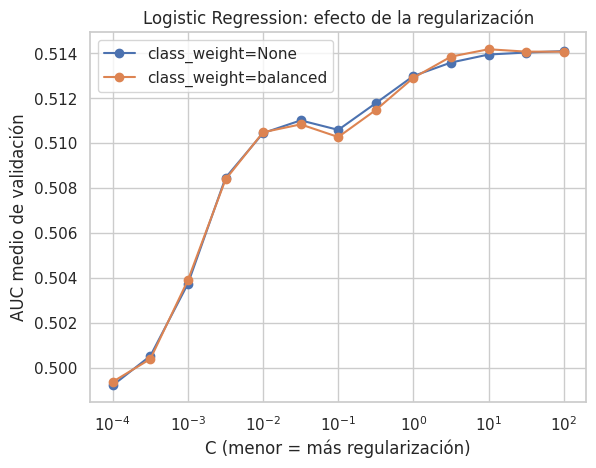

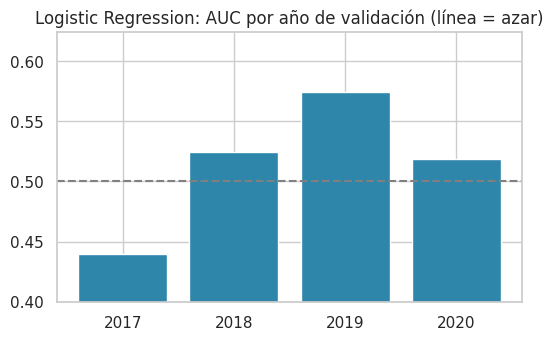

In [ ]:
pipe_lr = build_pipeline(LogisticRegression(max_iter=5000, random_state=SEED), escalar=True)
grid_lr = {'model__C': np.logspace(-4, 2, 13), 'model__class_weight': [None, 'balanced']}
search_lr = buscar(pipe_lr, grid_lr)
display(tabla_cv(search_lr))

# AUC de validación según la regularización
r = pd.DataFrame(search_lr.cv_results_)
for cw in [None, 'balanced']:
    s = r[r['param_model__class_weight'].astype(str) == str(cw)].sort_values('param_model__C')
    plt.semilogx(s['param_model__C'].astype(float), s['mean_test_roc_auc'], 'o-', label=f'class_weight={cw}')
plt.xlabel('C (menor = más regularización)'); plt.ylabel('AUC medio de validación'); plt.legend(); plt.title('Logistic Regression: efecto de la regularización')
plt.show()
grafico_cv(search_lr, 'Logistic Regression')

Mejores hiperparámetros: {'model__C': np.float64(10.0), 'model__class_weight': 'balanced'}
AUC entrenamiento: 0.598 | AUC validación temporal: 0.514 | AUC prueba: 0.515


,Logistic Regression
Accuracy,0.5040
Precision,0.4764
Recall,0.4721
F1-Score,0.4742
ROC-AUC,0.5155
Brier Score,0.2575
PR-AUC,0.4963
Log-Loss,0.7103
ECE,0.0903
Pendiente calibración,0.0831


               precision    recall  f1-score   support

No supera RSP       0.53      0.53      0.53       995
   Supera RSP       0.48      0.47      0.47       896

     accuracy                           0.50      1891
    macro avg       0.50      0.50      0.50      1891
 weighted avg       0.50      0.50      0.50      1891



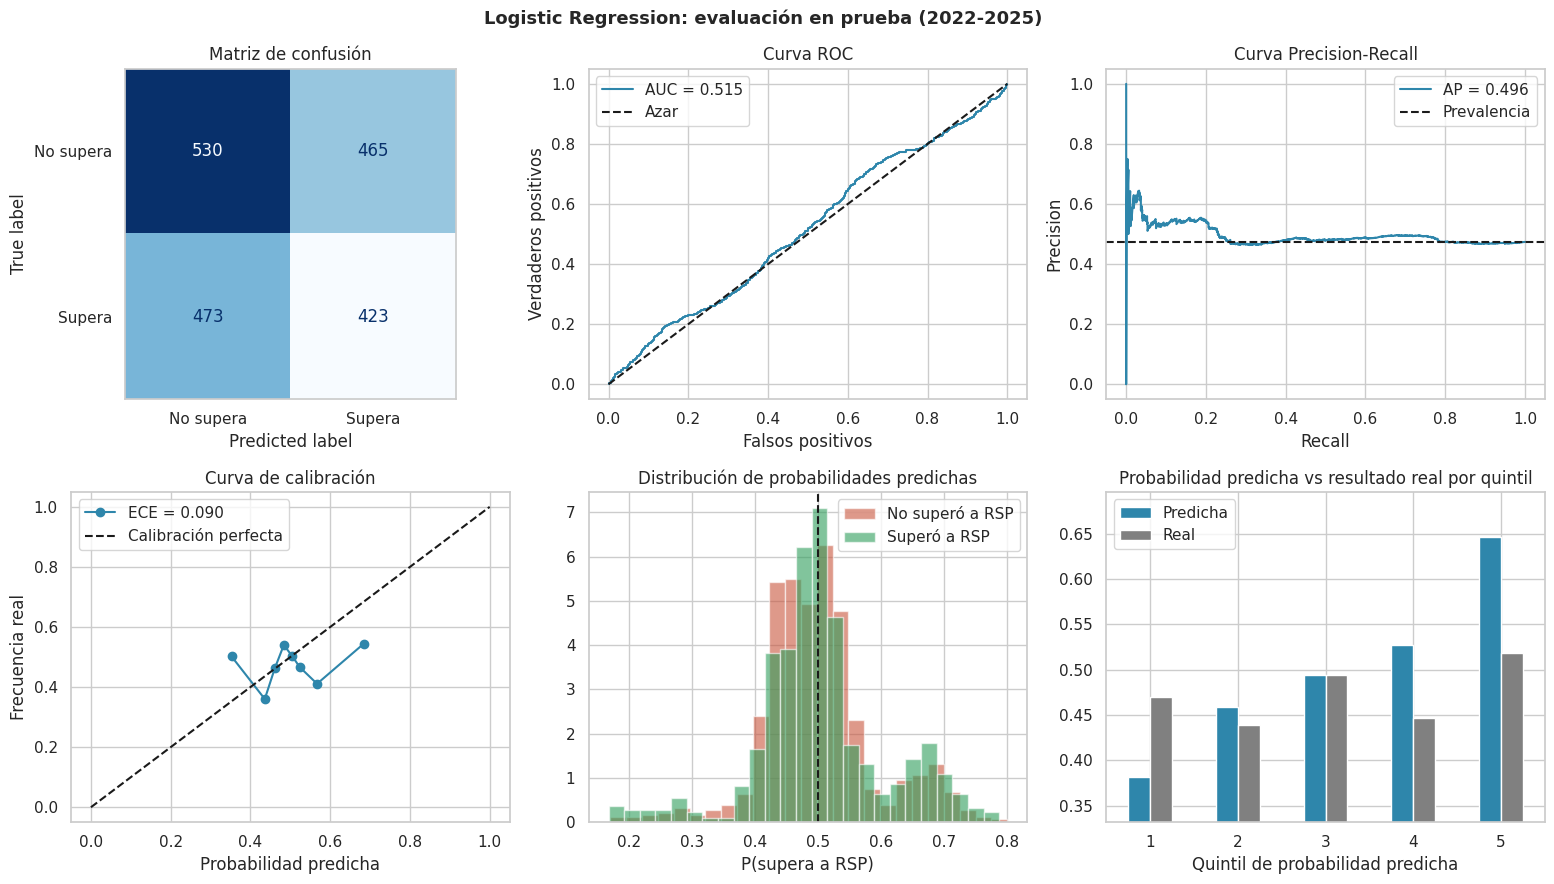

In [ ]:
reporte_modelo('Logistic Regression', search_lr)

**Cómo leer las gráficas de evaluación:**
- *Matriz de confusión:* aciertos y errores con umbral 50 %.
- *Curva ROC:* cuanto más alejada de la diagonal (azar), mejor ordena el modelo.
- *Curva de calibración:* si los puntos siguen la diagonal, las probabilidades son confiables.
- *Quintiles:* si el modelo funcionara, la tasa real debería subir de Q1 a Q5.

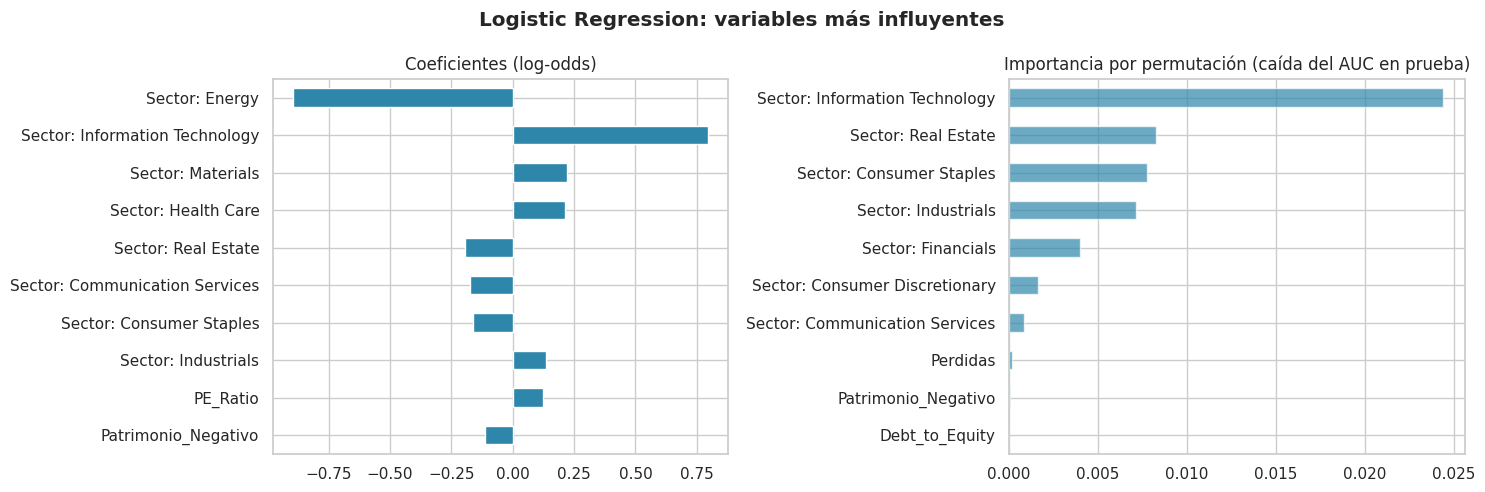

,Coeficiente,Odds ratio
Sector: Energy,-0.894,0.409
Sector: Information Technology,0.794,2.213
Sector: Materials,0.222,1.249
Sector: Health Care,0.214,1.239
Sector: Real Estate,-0.196,0.822
Sector: Communication Services,-0.175,0.839
Sector: Consumer Staples,-0.164,0.849
Sector: Industrials,0.137,1.147


- Sector: Energy: reduce la probabilidad de superar a RSP (odds ratio = 0.41)
- Sector: Information Technology: aumenta la probabilidad de superar a RSP (odds ratio = 2.21)
- Sector: Materials: aumenta la probabilidad de superar a RSP (odds ratio = 1.25)
- Sector: Health Care: aumenta la probabilidad de superar a RSP (odds ratio = 1.24)
- Sector: Real Estate: reduce la probabilidad de superar a RSP (odds ratio = 0.82)


In [ ]:
# Coeficientes (variables continuas estandarizadas, por lo que son comparables) y odds ratio
coef = pd.Series(search_lr.best_estimator_.named_steps['model'].coef_[0], index=ORDEN)
perm_lr = grafico_importancias('Logistic Regression', search_lr.best_estimator_, coef, 'Coeficientes (log-odds)')

tabla_coef = pd.DataFrame({'Coeficiente': coef, 'Odds ratio': np.exp(coef)}).sort_values('Coeficiente', key=abs, ascending=False)
display(tabla_coef.head(8).rename(index=corto).round(3))
for variable, fila in tabla_coef.head(5).iterrows():
    efecto = 'aumenta' if fila['Coeficiente'] > 0 else 'reduce'
    print(f'- {corto(variable)}: {efecto} la probabilidad de superar a RSP (odds ratio = {fila["Odds ratio"]:.2f})')

**Interpretación.** El signo del coeficiente indica la dirección del efecto (manteniendo el resto constante) y el odds ratio su magnitud: 1.5 significa que las probabilidades de superar a RSP aumentan 50 %; 0.5 que se reducen a la mitad. Si la importancia por permutación es cercana a cero, el modelo apenas obtiene capacidad predictiva fiable de esa variable.

**Limitaciones.** Supone relaciones lineales (en log-odds) y no captura interacciones; los datos financieros tienen colas pesadas y la señal es débil, por lo que se esperan métricas cercanas al azar.

## 6. Random Forest
**Idea:** conjunto de muchos árboles de decisión entrenados con submuestras de datos y variables; la probabilidad es el promedio de los árboles. Captura relaciones no lineales e interacciones, pero puede sobreajustar.

**Control de sobreajuste:** profundidad máxima (`max_depth`), tamaño mínimo de hoja (`min_samples_leaf`), submuestreo (`max_samples`, `max_features`). Se usa búsqueda aleatoria (30 combinaciones) con la misma validación temporal.

,AUC medio,AUC desv.,Brier medio,Parámetros
0,0.5240,0.0090,0.2587,"n_estimators=300, min_samples_leaf=5, max_samp..."
1,0.5232,0.0084,0.2573,"n_estimators=300, min_samples_leaf=5, max_samp..."
2,0.5218,0.0086,0.2609,"n_estimators=200, min_samples_leaf=5, max_samp..."
3,0.5209,0.0050,0.2593,"n_estimators=200, min_samples_leaf=5, max_samp..."
4,0.5196,0.0074,0.2576,"n_estimators=200, min_samples_leaf=10, max_sam..."
5,0.5176,0.0052,0.2584,"n_estimators=200, min_samples_leaf=5, max_samp..."
6,0.5170,0.0064,0.2581,"n_estimators=300, min_samples_leaf=5, max_samp..."
7,0.5164,0.0081,0.2586,"n_estimators=300, min_samples_leaf=5, max_samp..."


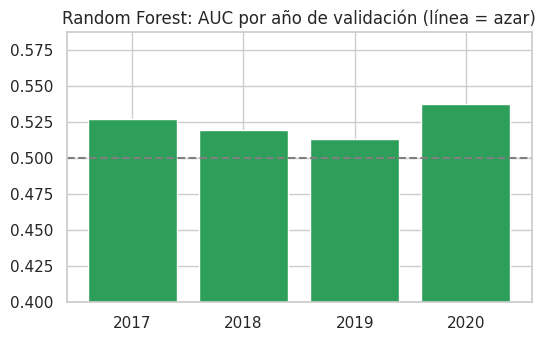

In [ ]:
pipe_rf = build_pipeline(RandomForestClassifier(random_state=SEED, n_jobs=1), escalar=False)
grid_rf = {'model__n_estimators': [200, 300, 500], 'model__max_depth': [3, 5, 8, 12, None],
           'model__min_samples_leaf': [5, 10, 20, 40, 80], 'model__max_features': ['sqrt', 0.3, 0.5],
           'model__max_samples': [0.5, 0.8, None], 'model__class_weight': [None, 'balanced_subsample']}
search_rf = buscar(pipe_rf, grid_rf, n_iter=30)
display(tabla_cv(search_rf))
grafico_cv(search_rf, 'Random Forest')

Mejores hiperparámetros: {'model__n_estimators': 300, 'model__min_samples_leaf': 5, 'model__max_samples': None, 'model__max_features': 0.3, 'model__max_depth': 8, 'model__class_weight': None}
AUC entrenamiento: 0.835 | AUC validación temporal: 0.524 | AUC prueba: 0.516


,Random Forest
Accuracy,0.5230
Precision,0.4958
Recall,0.3962
F1-Score,0.4404
ROC-AUC,0.5159
Brier Score,0.2566
PR-AUC,0.4906
Log-Loss,0.7085
ECE,0.0715
Pendiente calibración,0.0754


               precision    recall  f1-score   support

No supera RSP       0.54      0.64      0.58       995
   Supera RSP       0.50      0.40      0.44       896

     accuracy                           0.52      1891
    macro avg       0.52      0.52      0.51      1891
 weighted avg       0.52      0.52      0.52      1891



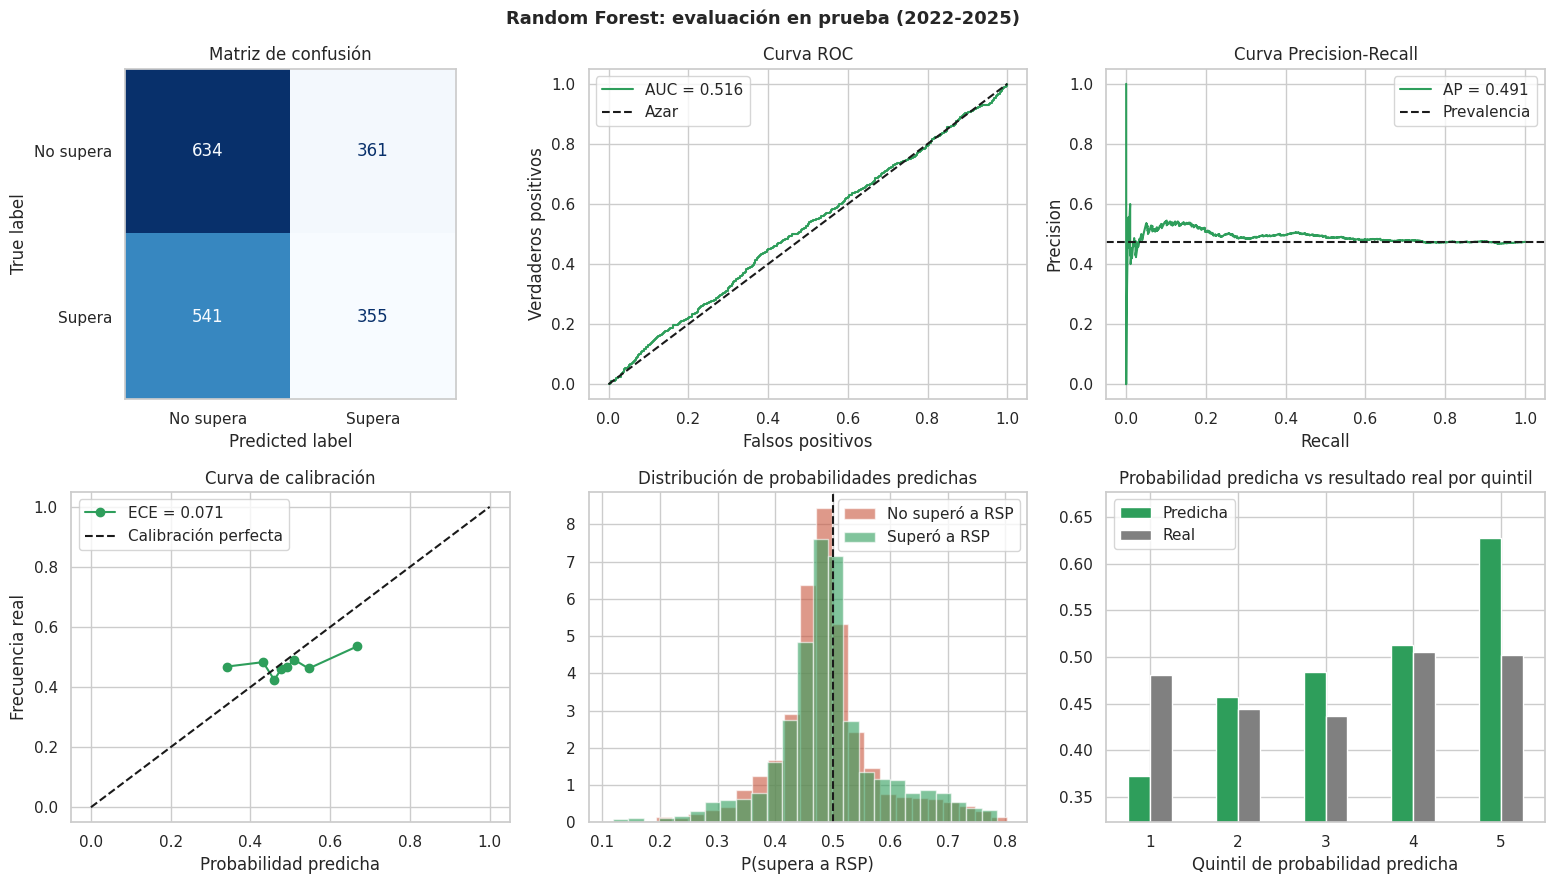

In [ ]:
reporte_modelo('Random Forest', search_rf)

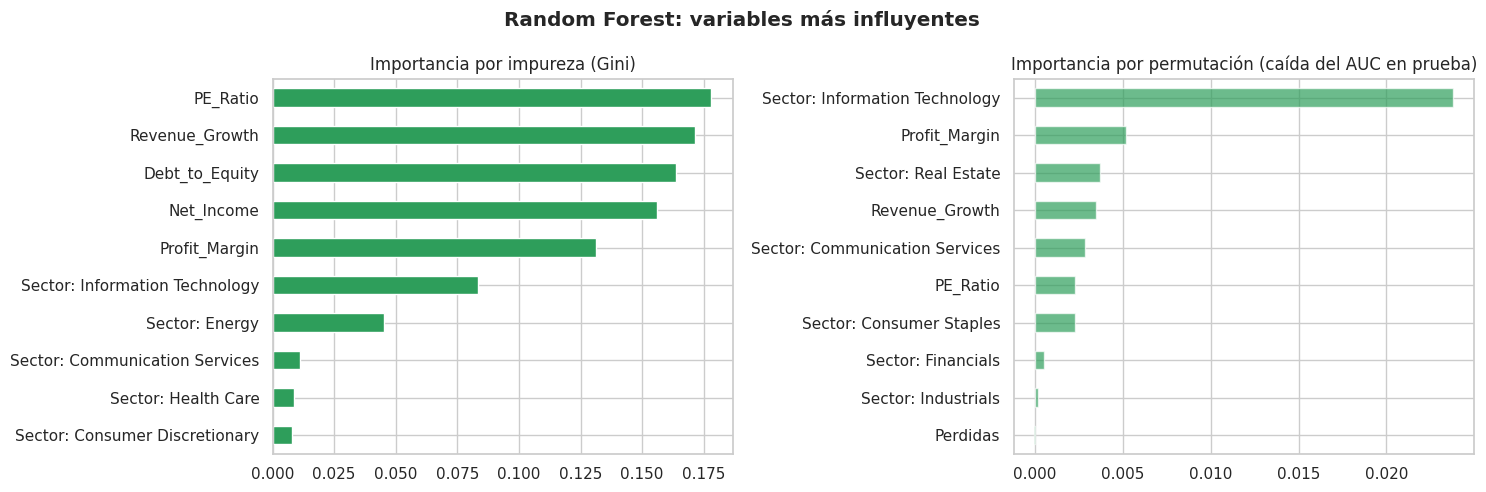

Más importantes por impureza: ['PE_Ratio', 'Revenue_Growth', 'Debt_to_Equity', 'Net_Income', 'Profit_Margin']
Permutación con efecto claro (> 2 desv.): ['Sector: Consumer Staples', 'Sector: Information Technology', 'Sector: Real Estate']


In [ ]:
imp_rf = pd.Series(search_rf.best_estimator_.named_steps['model'].feature_importances_, index=ORDEN)
perm_rf = grafico_importancias('Random Forest', search_rf.best_estimator_, imp_rf, 'Importancia por impureza (Gini)')
print('Más importantes por impureza:', [corto(c) for c in imp_rf.sort_values(ascending=False).index[:5]])
print('Permutación con efecto claro (> 2 desv.):', [corto(c) for c in perm_rf[perm_rf['media'] > 2 * perm_rf['std']].index] or 'ninguna')

**Interpretación.** La importancia por impureza se calcula con datos de entrenamiento y tiende a favorecer variables continuas con muchos valores distintos; por eso se contrasta con la importancia por permutación en prueba. Una variable importante por impureza pero sin efecto al permutarla indica que el bosque la usa para ajustar ruido.

**Señal de sobreajuste a vigilar:** si el AUC de entrenamiento es mucho mayor que el de validación y prueba, el modelo está memorizando.

## 7. XGBoost
**Idea:** árboles pequeños construidos uno tras otro, cada uno corrigiendo los errores de los anteriores (*gradient boosting*). Es potente pero propenso a sobreajustar con datos ruidosos.

**Control de sobreajuste:** árboles poco profundos (`max_depth`), tasa de aprendizaje baja (`learning_rate`), submuestreo de filas y columnas (`subsample`, `colsample_bytree`), `min_child_weight` y regularización (`reg_lambda`, `reg_alpha`, `gamma`). Se usa búsqueda aleatoria (40 combinaciones).

,AUC medio,AUC desv.,Brier medio,Parámetros
0,0.5352,0.0182,0.2516,"subsample=1.0, reg_lambda=1, reg_alpha=0.1, n_..."
1,0.5303,0.0129,0.2515,"subsample=1.0, reg_lambda=1, reg_alpha=0, n_es..."
2,0.5291,0.0123,0.2506,"subsample=1.0, reg_lambda=10, reg_alpha=0.1, n..."
3,0.5265,0.0207,0.2510,"subsample=0.6, reg_lambda=5, reg_alpha=1, n_es..."
4,0.5254,0.0297,0.2514,"subsample=1.0, reg_lambda=30, reg_alpha=1, n_e..."
5,0.5250,0.0195,0.2513,"subsample=1.0, reg_lambda=30, reg_alpha=1, n_e..."
6,0.5243,0.0277,0.2540,"subsample=1.0, reg_lambda=1, reg_alpha=0, n_es..."
7,0.5237,0.0146,0.2588,"subsample=0.8, reg_lambda=10, reg_alpha=0.1, n..."


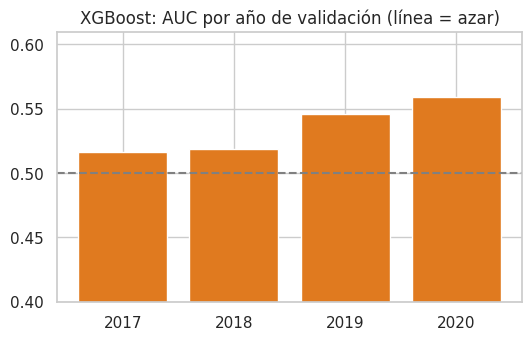

In [ ]:
pipe_xgb = build_pipeline(XGBClassifier(objective='binary:logistic', eval_metric='logloss', tree_method='hist',
                                        random_state=SEED, n_jobs=1, verbosity=0), escalar=False)
grid_xgb = {'model__n_estimators': [100, 200, 400], 'model__max_depth': [2, 3, 4, 5],
            'model__learning_rate': [0.01, 0.02, 0.05, 0.1], 'model__subsample': [0.6, 0.8, 1.0],
            'model__colsample_bytree': [0.5, 0.8, 1.0], 'model__min_child_weight': [1, 5, 10, 20],
            'model__reg_lambda': [1, 5, 10, 30], 'model__reg_alpha': [0, 0.1, 1], 'model__gamma': [0, 1, 5]}
search_xgb = buscar(pipe_xgb, grid_xgb, n_iter=40)
display(tabla_cv(search_xgb))
grafico_cv(search_xgb, 'XGBoost')

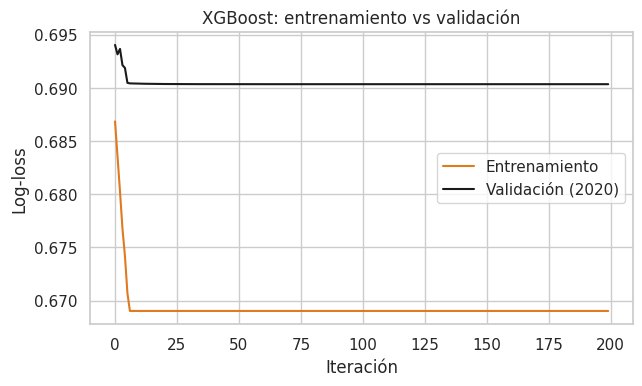

In [ ]:
# Diagnóstico de sobreajuste: pérdida (log-loss) por iteración en el último fold de validación (año 2020)
tr, va = CV[-1]
pre = clone(search_xgb.best_estimator_.named_steps['pre']).fit(X_train.iloc[tr])
Xa, Xb = pre.transform(X_train.iloc[tr]), pre.transform(X_train.iloc[va])
mdl = clone(search_xgb.best_estimator_.named_steps['model']).set_params(eval_metric='logloss')
mdl.fit(Xa, y_train.iloc[tr], eval_set=[(Xa, y_train.iloc[tr]), (Xb, y_train.iloc[va])], verbose=False)
curvas = mdl.evals_result()
plt.figure(figsize=(7, 3.8))
plt.plot(curvas['validation_0']['logloss'], label='Entrenamiento', color=COLORES['XGBoost'])
plt.plot(curvas['validation_1']['logloss'], label='Validación (2020)', color='k')
plt.xlabel('Iteración'); plt.ylabel('Log-loss'); plt.title('XGBoost: entrenamiento vs validación'); plt.legend(); plt.show()

**Cómo leerlo:** si la pérdida de entrenamiento sigue bajando mientras la de validación sube o se estanca, el modelo está sobreajustando.

Mejores hiperparámetros: {'model__subsample': 1.0, 'model__reg_lambda': 1, 'model__reg_alpha': 0.1, 'model__n_estimators': 200, 'model__min_child_weight': 1, 'model__max_depth': 5, 'model__learning_rate': 0.1, 'model__gamma': 5, 'model__colsample_bytree': 0.8}
AUC entrenamiento: 0.657 | AUC validación temporal: 0.535 | AUC prueba: 0.519


,XGBoost
Accuracy,0.5341
Precision,0.5146
Recall,0.2958
F1-Score,0.3756
ROC-AUC,0.5189
Brier Score,0.2525
PR-AUC,0.4893
Log-Loss,0.6986
ECE,0.0429
Pendiente calibración,0.0986


               precision    recall  f1-score   support

No supera RSP       0.54      0.75      0.63       995
   Supera RSP       0.51      0.30      0.38       896

     accuracy                           0.53      1891
    macro avg       0.53      0.52      0.50      1891
 weighted avg       0.53      0.53      0.51      1891



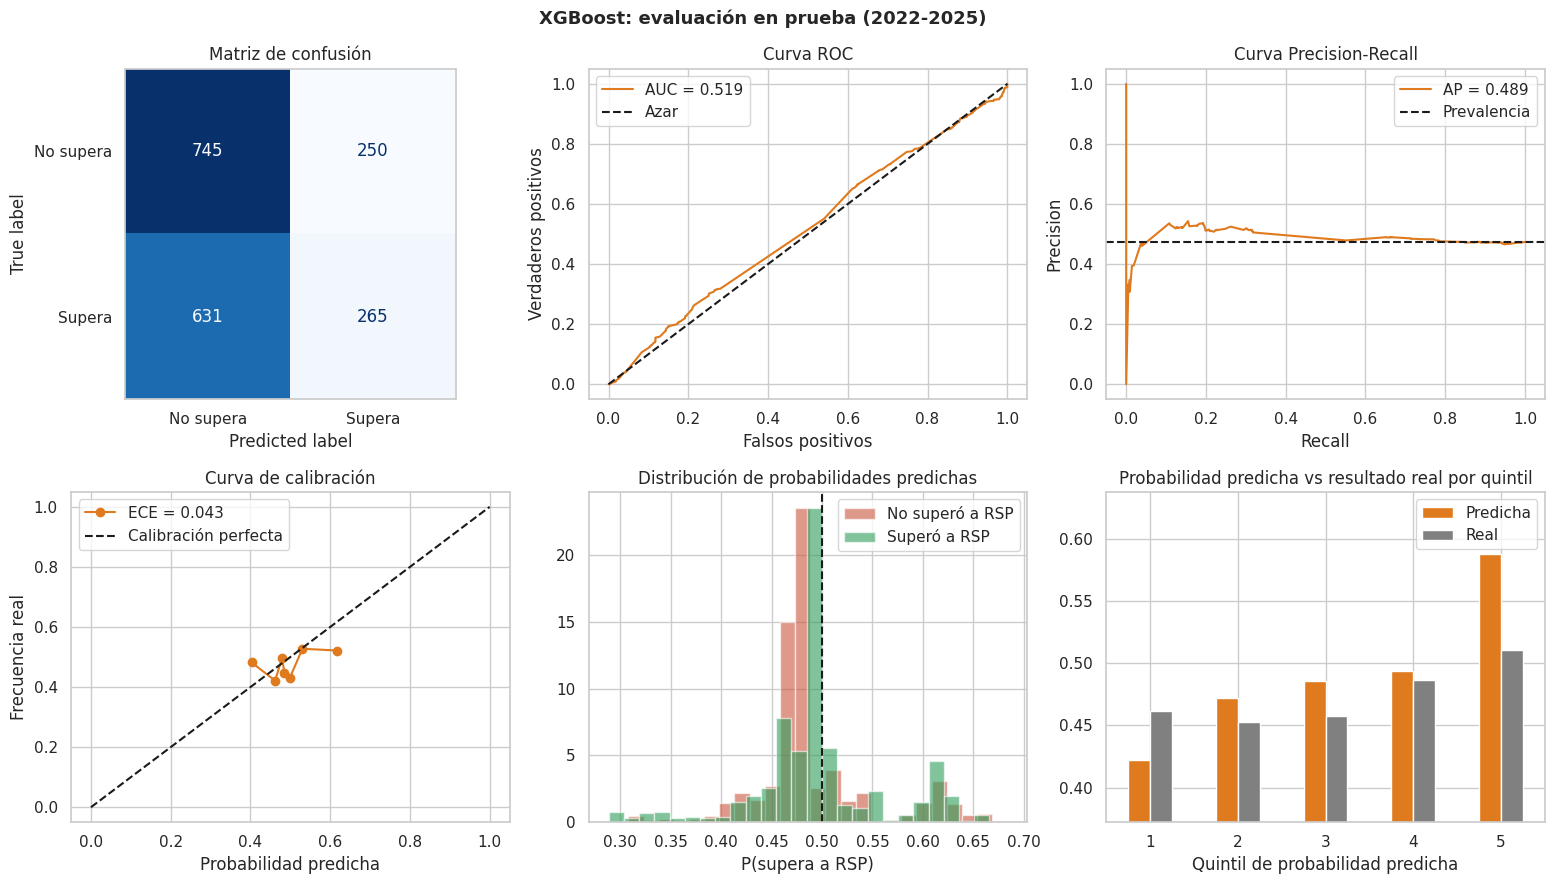

In [ ]:
reporte_modelo('XGBoost', search_xgb)

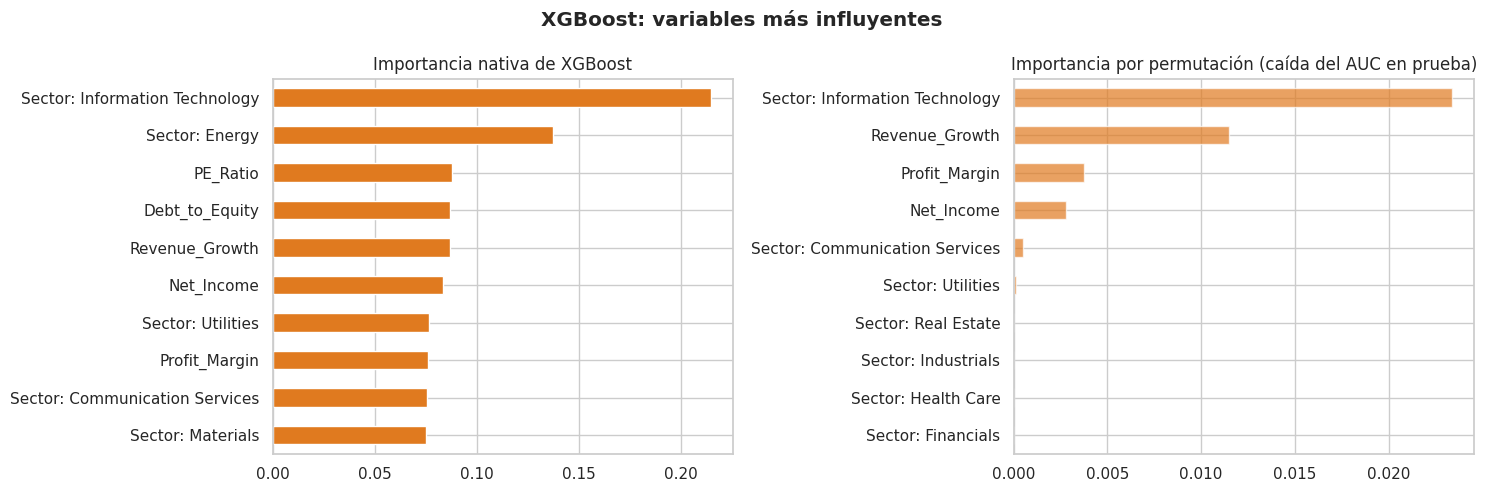

Más importantes (nativa): ['Sector: Information Technology', 'Sector: Energy', 'PE_Ratio', 'Debt_to_Equity', 'Revenue_Growth']
Permutación con efecto claro (> 2 desv.): ['Revenue_Growth', 'Sector: Information Technology']


In [ ]:
imp_xgb = pd.Series(search_xgb.best_estimator_.named_steps['model'].feature_importances_, index=ORDEN)
perm_xgb = grafico_importancias('XGBoost', search_xgb.best_estimator_, imp_xgb, 'Importancia nativa de XGBoost')
print('Más importantes (nativa):', [corto(c) for c in imp_xgb.sort_values(ascending=False).index[:5]])
print('Permutación con efecto claro (> 2 desv.):', [corto(c) for c in perm_xgb[perm_xgb['media'] > 2 * perm_xgb['std']].index] or 'ninguna')

## 8. Evaluación estadística
Con un AUC cercano a 0.5, hay que comprobar si las diferencias entre modelos son reales o ruido. Se hacen tres análisis:
1. **Bootstrap** (1 000 remuestreos de la prueba): intervalos de confianza del AUC y del Brier, y de las diferencias entre modelos.
2. **Estabilidad por año:** si el desempeño es consistente en el tiempo.
3. **Control con etiquetas permutadas:** se entrena con etiquetas mezcladas al azar; el AUC debe ser ≈ 0.5. Si fuera mucho mayor, habría fuga de información.

*Nota:* el bootstrap supone filas independientes; como las de un mismo año comparten el resultado de RSP, los intervalos son algo optimistas.

,ROC-AUC,AUC IC95 inf,AUC IC95 sup,Brier,Brier IC95 inf,Brier IC95 sup
Logistic Regression,0.5155,0.4888,0.5390,0.2575,0.2533,0.2618
Random Forest,0.5159,0.4891,0.5417,0.2566,0.2524,0.2613
XGBoost,0.5189,0.4923,0.5434,0.2525,0.2498,0.2554


Referencia: AUC del azar = 0.5 | Brier de predecir siempre la prevalencia = 0.2495


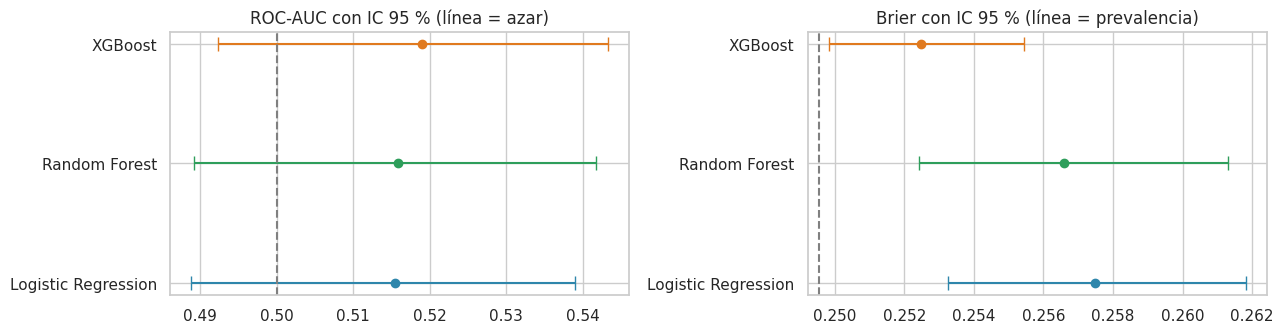

,ΔAUC,IC95 inf,IC95 sup
Comparación,,,
Logistic Regression - Random Forest,-0.0000,-0.0215,0.0218
Logistic Regression - XGBoost,-0.0036,-0.0275,0.0205
Random Forest - XGBoost,-0.0036,-0.0206,0.0127


In [ ]:
MODELOS = list(RES)
yv = y_test.values
rng = np.random.RandomState(SEED)
auc_b = {k: [] for k in MODELOS}; brier_b = {k: [] for k in MODELOS}
for _ in range(1000):
    i = rng.randint(0, len(yv), len(yv))              # remuestreo con reemplazo (mismas filas para todos los modelos)
    if yv[i].min() == yv[i].max():
        continue
    for k in MODELOS:
        auc_b[k].append(roc_auc_score(yv[i], RES[k]['p'][i]))
        brier_b[k].append(brier_score_loss(yv[i], RES[k]['p'][i]))

ic = lambda v: np.percentile(v, [2.5, 97.5])
BRIER_BASE = brier_score_loss(yv, np.full(len(yv), y_train.mean()))     # Brier de predecir siempre la prevalencia
tabla_ic = pd.DataFrame({k: {'ROC-AUC': RES[k]['m']['ROC-AUC'], 'AUC IC95 inf': ic(auc_b[k])[0], 'AUC IC95 sup': ic(auc_b[k])[1],
                             'Brier': RES[k]['m']['Brier Score'], 'Brier IC95 inf': ic(brier_b[k])[0], 'Brier IC95 sup': ic(brier_b[k])[1]}
                         for k in MODELOS}).T
display(tabla_ic.round(4))
print(f'Referencia: AUC del azar = 0.5 | Brier de predecir siempre la prevalencia = {BRIER_BASE:.4f}')

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
for a, boot, key, ref, tit in [(ax[0], auc_b, 'ROC-AUC', 0.5, 'ROC-AUC con IC 95 % (línea = azar)'),
                               (ax[1], brier_b, 'Brier Score', BRIER_BASE, 'Brier con IC 95 % (línea = prevalencia)')]:
    for j, k in enumerate(MODELOS):
        v = RES[k]['m'][key]; lo, hi = ic(boot[k])
        a.errorbar(v, j, xerr=[[v - lo], [hi - v]], fmt='o', color=COLORES[k], capsize=5)
    a.axvline(ref, color='gray', ls='--'); a.set_yticks(range(len(MODELOS))); a.set_yticklabels(MODELOS); a.set_title(tit)
plt.tight_layout(); plt.show()

# Diferencias de AUC entre pares de modelos
filas = []
for i, a in enumerate(MODELOS):
    for b in MODELOS[i + 1:]:
        d = np.array(auc_b[a]) - np.array(auc_b[b])
        filas.append({'Comparación': f'{a} - {b}', 'ΔAUC': d.mean(), 'IC95 inf': np.percentile(d, 2.5), 'IC95 sup': np.percentile(d, 97.5)})
display(pd.DataFrame(filas).set_index('Comparación').round(4))
for k in MODELOS:
    if RES[k]['m']['ROC-AUC'] >= 0.80:
        print(f'ALERTA: ROC-AUC >= 0.80 en {k}. Investigar fuga de información.')

**Cómo leerlo:** si el intervalo de confianza del AUC incluye 0.5, no hay evidencia sólida de que el modelo supere al azar. Si el intervalo de la diferencia entre dos modelos incluye 0, esa diferencia no es concluyente.

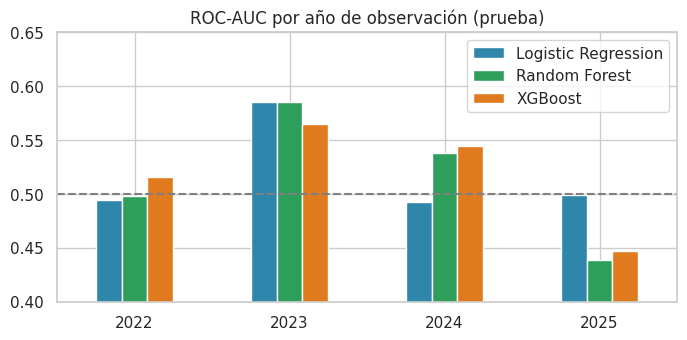

AUC con etiquetas permutadas (esperado ≈ 0.50):
  Logistic Regression: 0.509 ± 0.026
  Random Forest: 0.518 ± 0.009
  XGBoost: 0.495 ± 0.007


In [ ]:
# Estabilidad por año de la prueba
anios_t = sorted(anio_test.unique())
auc_anio = pd.DataFrame({k: [roc_auc_score(yv[anio_test.values == a], RES[k]['p'][anio_test.values == a]) for a in anios_t]
                         for k in MODELOS}, index=anios_t)
auc_anio.plot.bar(figsize=(8, 3.5), color=[COLORES[k] for k in MODELOS], rot=0)
plt.axhline(0.5, color='gray', ls='--'); plt.ylim(0.4, 0.65); plt.title('ROC-AUC por año de observación (prueba)'); plt.show()

# Control de fuga: entrenar con etiquetas permutadas -> el AUC de prueba debe ser ≈ 0.5
rp = np.random.RandomState(SEED)
perm_auc = {k: [roc_auc_score(yv, clone(RES[k]['pipe']).fit(X_train, rp.permutation(y_train.values)).predict_proba(X_test)[:, 1])
                for _ in range(5)] for k in MODELOS}
print('AUC con etiquetas permutadas (esperado ≈ 0.50):')
for k, v in perm_auc.items():
    print(f'  {k}: {np.mean(v):.3f} ± {np.std(v):.3f}')

## 9. Comparación y selección del mejor modelo
Se compara con la tabla pedida y se elige el modelo con el mejor **rango medio** entre ROC-AUC (capacidad de ordenar), Brier (calidad de la probabilidad) y ECE (calibración). **No se elige por Accuracy.**

In [ ]:
METRICAS = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'Brier Score']
tabla = pd.DataFrame({k: {m: RES[k]['m'][m] for m in METRICAS} for k in MODELOS})
tabla.index.name = 'Métrica'
display(tabla.round(4))

ext = pd.DataFrame({k: {m: RES[k]['m'][m] for m in ['PR-AUC', 'Log-Loss', 'ECE', 'Pendiente calibración']} for k in MODELOS})
ext.loc['Brier skill vs prevalencia'] = [1 - RES[k]['m']['Brier Score'] / BRIER_BASE for k in MODELOS]
ext.loc['AUC validación temporal'] = [RES[k]['cv_auc'] for k in MODELOS]
display(ext.round(4))

,Logistic Regression,Random Forest,XGBoost
Métrica,,,
Accuracy,0.5040,0.5230,0.5341
Precision,0.4764,0.4958,0.5146
Recall,0.4721,0.3962,0.2958
F1-Score,0.4742,0.4404,0.3756
ROC-AUC,0.5155,0.5159,0.5189
Brier Score,0.2575,0.2566,0.2525


,Logistic Regression,Random Forest,XGBoost
PR-AUC,0.4963,0.4906,0.4893
Log-Loss,0.7103,0.7085,0.6986
ECE,0.0903,0.0715,0.0429
Pendiente calibración,0.0831,0.0754,0.0986
Brier skill vs prevalencia,-0.0318,-0.0282,-0.0118
AUC validación temporal,0.5142,0.5240,0.5352


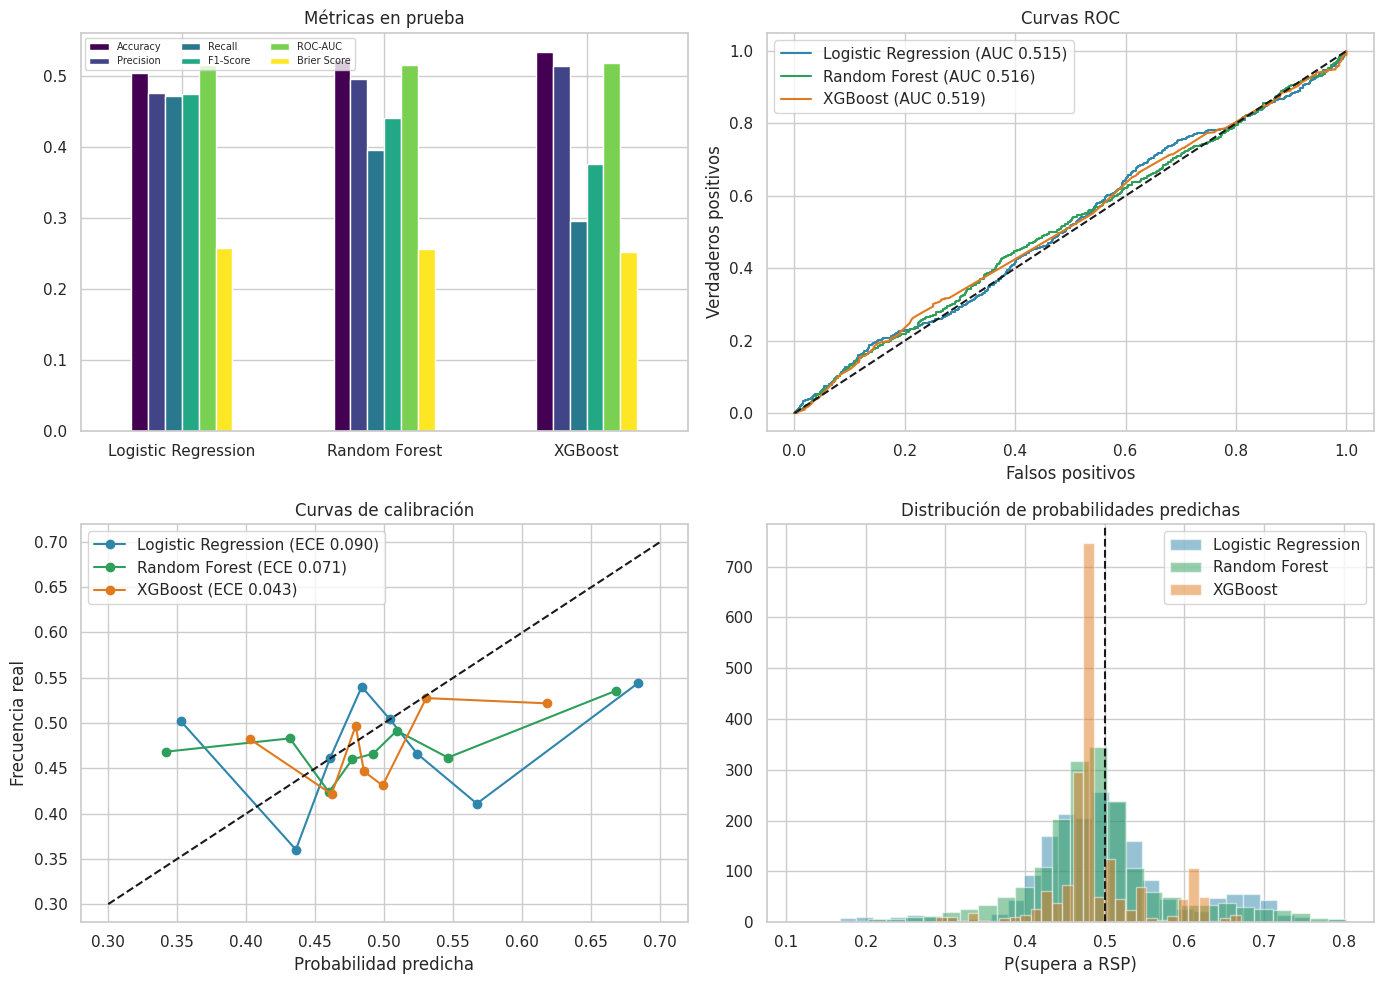

In [ ]:
# Comparación visual: métricas, curva ROC, calibración y distribución de probabilidades
fig, ax = plt.subplots(2, 2, figsize=(14, 10)); ax = ax.ravel()
tabla.T.plot.bar(ax=ax[0], rot=0, colormap='viridis'); ax[0].set_title('Métricas en prueba'); ax[0].legend(fontsize=7, ncol=3)
for k in MODELOS:
    fpr, tpr, _ = roc_curve(yv, RES[k]['p'])
    ax[1].plot(fpr, tpr, color=COLORES[k], label=f"{k} (AUC {RES[k]['m']['ROC-AUC']:.3f})")
    real, pred = calibration_curve(yv, RES[k]['p'], n_bins=8, strategy='quantile')
    ax[2].plot(pred, real, 'o-', color=COLORES[k], label=f"{k} (ECE {RES[k]['m']['ECE']:.3f})")
    ax[3].hist(RES[k]['p'], bins=30, alpha=.5, color=COLORES[k], label=k)
ax[1].plot([0, 1], [0, 1], 'k--'); ax[1].set(title='Curvas ROC', xlabel='Falsos positivos', ylabel='Verdaderos positivos'); ax[1].legend()
ax[2].plot([0.3, 0.7], [0.3, 0.7], 'k--'); ax[2].set(title='Curvas de calibración', xlabel='Probabilidad predicha', ylabel='Frecuencia real'); ax[2].legend()
ax[3].axvline(UMBRAL, color='k', ls='--'); ax[3].set(title='Distribución de probabilidades predichas', xlabel='P(supera a RSP)'); ax[3].legend()
plt.tight_layout(); plt.show()

In [ ]:
# Selección: menor rango medio en ROC-AUC (mayor), Brier (menor) y ECE (menor)
rango = pd.DataFrame({'ROC-AUC': tabla.loc['ROC-AUC'].rank(ascending=False), 'Brier': tabla.loc['Brier Score'].rank(),
                      'ECE': ext.loc['ECE'].rank()})
rango['Rango medio'] = rango.mean(axis=1)
rango = rango.sort_values('Rango medio'); display(rango)
MEJOR = rango.index[0]
print(f'Modelo seleccionado: {MEJOR}')

for otro in MODELOS:
    if otro != MEJOR:
        d = np.array(auc_b[MEJOR]) - np.array(auc_b[otro]); lo, hi = np.percentile(d, [2.5, 97.5])
        print(f'  vs {otro}: ΔAUC = {d.mean():+.3f}, IC95 [{lo:+.3f}, {hi:+.3f}] -> {"diferencia distinguible" if lo > 0 else "diferencia NO concluyente"}')
if ic(auc_b[MEJOR])[0] <= 0.5:
    print('AVISO: el IC95 del ROC-AUC incluye 0.5; no hay evidencia sólida de capacidad predictiva superior al azar.')
if ext.loc['Brier skill vs prevalencia', MEJOR] <= 0:
    print('AVISO: el Brier no mejora al de predecir siempre la prevalencia; las probabilidades no aportan información calibrada.')

,ROC-AUC,Brier,ECE,Rango medio
XGBoost,1.0,1.0,1.0,1.0
Random Forest,2.0,2.0,2.0,2.0
Logistic Regression,3.0,3.0,3.0,3.0


Modelo seleccionado: XGBoost
  vs Logistic Regression: ΔAUC = +0.004, IC95 [-0.020, +0.028] -> diferencia NO concluyente
  vs Random Forest: ΔAUC = +0.004, IC95 [-0.013, +0.021] -> diferencia NO concluyente
AVISO: el IC95 del ROC-AUC incluye 0.5; no hay evidencia sólida de capacidad predictiva superior al azar.
AVISO: el Brier no mejora al de predecir siempre la prevalencia; las probabilidades no aportan información calibrada.


**Cómo defender la selección:** se combinan ranking (ROC-AUC), calidad de la probabilidad (Brier) y calibración (ECE) porque el objetivo es entregar probabilidades útiles. Si los intervalos de confianza se solapan, la diferencia entre modelos **no es concluyente** y así debe presentarse. Un *Brier skill* ≤ 0 indica que el modelo no mejora a predecir siempre la prevalencia.

## 10. Predicción individual
La función `predecir_empresa()` recibe los indicadores de una empresa y su sector, y usa **el mismo pipeline entrenado** (mismo preprocesamiento). No necesita conocer el Target.

Interpretación: ≥ 55 % favorable, ≤ 45 % desfavorable, entre 45 % y 55 % incierto (la banda es una convención de este trabajo). El resultado por umbral usa el corte exacto del 50 %.

In [ ]:
def predecir_empresa(indicadores, sector, modelo='Logistic Regression', banda=0.05):
    """indicadores: dict con Revenue_Growth (%), Net_Income (millones USD), Profit_Margin (%), Debt_to_Equity, PE_Ratio.
    Opcionales: Patrimonio_Negativo y Perdidas (0/1). Si falta Perdidas se infiere (Net_Income < 0).
    modelo: nombre de un modelo o 'todos'."""
    if modelo == 'todos':
        return pd.DataFrame([predecir_empresa(indicadores, sector, m, banda) for m in RES]).set_index('Modelo')
    if sector not in SECTORES:
        raise ValueError(f'Sector no válido. Opciones: {SECTORES}')
    fila = {c: np.nan if indicadores.get(c) is None else float(indicadores[c]) for c in CONT}   # nulos -> los imputa el pipeline
    fila['Perdidas'] = int(indicadores.get('Perdidas', fila['Net_Income'] < 0))
    fila['Patrimonio_Negativo'] = int(indicadores.get('Patrimonio_Negativo', 0))
    for c in SECT:
        fila[c] = int(c == f'GICS Sector_{sector}')
    p = RES[modelo]['pipe'].predict_proba(pd.DataFrame([fila])[FEATURES])[0, 1]

    if p >= 0.5 + banda:   texto = 'Mayor probabilidad de superar a RSP.'
    elif p <= 0.5 - banda: texto = 'Mayor probabilidad de no superar a RSP.'
    else:                  texto = 'Resultado incierto: probabilidad cercana al 50 %, sin evidencia predictiva fuerte.'
    return {'Modelo': modelo, 'P(supera RSP)': round(p, 4), 'P(no supera RSP)': round(1 - p, 4),
            'Resultado (umbral 50 %)': 'Supera RSP' if p >= UMBRAL else 'No supera RSP', 'Interpretación': texto}

# Ejemplo 1: una fila real de la prueba (el Target no se usa en la predicción)
fila_real = X_test.iloc[0]
sector_real = fila_real[SECT].idxmax().replace('GICS Sector_', '')
print('Sector:', sector_real, '|', fila_real[CONT + BIN].round(2).to_dict())
display(predecir_empresa(fila_real[CONT + BIN].to_dict(), sector_real, modelo='todos'))
print('Resultado real (solo para contraste):', 'superó a RSP' if y_test.iloc[0] == 1 else 'no superó a RSP')

# Ejemplo 2: valores ilustrativos inventados, solo para mostrar el uso de la función
display(predecir_empresa({'Revenue_Growth': 8.0, 'Net_Income': 1500, 'Profit_Margin': 12.0, 'Debt_to_Equity': 0.9, 'PE_Ratio': 22.0},
                         'Information Technology', modelo=MEJOR))

Sector: Health Care | {'Revenue_Growth': 8.37, 'Net_Income': 1254.0, 'Profit_Margin': 18.31, 'Debt_to_Equity': 0.52, 'PE_Ratio': 35.65, 'Patrimonio_Negativo': 0.0, 'Perdidas': 0.0}


,P(supera RSP),P(no supera RSP),Resultado (umbral 50 %),Interpretación
Modelo,,,,
Logistic Regression,0.5410,0.4590,Supera RSP,Resultado incierto: probabilidad cercana al 50...
Random Forest,0.5369,0.4631,Supera RSP,Resultado incierto: probabilidad cercana al 50...
XGBoost,0.4853,0.5147,No supera RSP,Resultado incierto: probabilidad cercana al 50...


Resultado real (solo para contraste): no superó a RSP


{'Modelo': 'XGBoost',
 'P(supera RSP)': np.float32(0.6114),
 'P(no supera RSP)': np.float32(0.3886),
 'Resultado (umbral 50 %)': 'Supera RSP',
 'Interpretación': 'Mayor probabilidad de superar a RSP.'}

## 11. Conclusiones y limitaciones

**Resultados.** La tabla de la sección 9 resume los tres modelos con los mismos datos, la misma separación temporal y la misma purga. La señal predictiva de estas variables financieras es débil: las correlaciones con Target son muy bajas y el documento de preparación ya anticipaba un ROC-AUC cercano a 0.55 como valor realista. El bootstrap (sección 8) indica si cada modelo se distingue del azar y si las diferencias entre modelos son concluyentes; el control con etiquetas permutadas descarta fuga de información en el *pipeline*. Un resultado cercano a 0.50 no es un error del código, sino evidencia de lo difícil que es predecir rendimientos relativos.

**Probabilidades.** `predict_proba()` no garantiza calibración. Se evaluó con la curva de calibración, el ECE, la pendiente de calibración (< 1 indica sobreconfianza) y el Brier frente a la prevalencia. Las probabilidades cercanas al 50 % deben leerse como incertidumbre, no como señal.

**Limitaciones**
- **Sesgo de supervivencia:** las empresas quebradas o adquiridas casi no aparecen en las fuentes, lo que tiende a sobreestimar el desempeño.
- **Sectores históricos** que pueden no coincidir con los actuales (los de empresas fuera del índice se recuperaron de otra fuente).
- **Diferencias contables** entre empresas e industrias (etiquetas XBRL no uniformes; bancos y aseguradoras con más datos faltantes).
- **Variables limitadas:** cinco indicadores financieros, dos indicadores binarios y sector; sin valoración relativa, momentum, calidad ni variables macroeconómicas.
- **Tamaño y periodo:** 4 825 observaciones en 2015-2025; el periodo de prueba (2022-2025) cubre pocos regímenes de mercado y las observaciones de un mismo año comparten el resultado de RSP.
- **Limpieza previa** (winsorización e imputación por año) no reversible; se mitigó reaplicándolas dentro del *pipeline*.
- **Sectores:** los coeficientes e importancias de sector reflejan el desempeño sectorial del periodo de entrenamiento, que puede no repetirse.
- **Purga:** reduce el entrenamiento efectivo (casi todo 2021 se descarta).
- **Dificultad inherente** de predecir rendimientos bursátiles.


